# Brujula Inmobiliaria - Entrega 3: modelado

**Grupo 5k10-09** - Gustavo Santino Giovannini, Rodrigo Luis Vargas,
Renzo Sahade, Garcia Zacarias, Santiago Bullaude

**Pregunta del proyecto.** Un aviso de alquiler de departamento en Mendoza,
esta sobrevalorado, en linea con el mercado, o es una oportunidad?

**Lo que se modela.** Una **regresion** sobre `precio_m2` (pesos por m2
cubierto). El modelo estima cuanto *deberia* pedir un aviso segun sus
caracteristicas, y la diferencia con lo que pide de verdad (el residuo) es
lo que la aplicacion de la Entrega 4 va a leer como sobrevalorado u
oportunidad.

**Dataset.** `resultados/20261013/` - 3539 avisos acumulados entre el 7 de
septiembre y el 13 de octubre.



## 0. Que cambio desde la Entrega 2

**Lo que nos marcaron en la Entrega 2:** dos de las cuatro hipotesis, H1 y
H3.

- **H1 (ARS contra USD):** habia que **unificar los precios a pesos** en vez
  de dejar afuera los avisos en dolares. **Resuelto** (seccion 0.1): se
  convierten con el dolar MEP del 13/10, porque en toda la ventana la
  cotizacion se movio menos de 2 %. Los avisos en USD entran al modelo, con
  una marca de que se publicaron en dolares.
- **H3 (precio por m2 contra distancia al centro):** habia que **separar por
  sectores de metros cuadrados** y recien ahi comparar con la distancia.
  **Resuelto** (seccion 0.2): en los departamentos chicos el efecto aparece
  (amarillo), en los grandes no, y la relacion tiene forma de U, que es lo
  que la correlacion global escondia.

**Cambios en el dataset.** El pipeline siguio corriendo todos los dias: el
dataset paso de **2504 a 3539 avisos**. El objetivo sigue siendo
`precio_m2`, ahora **todo en pesos**. Las columnas que entran son las de la
tabla de columnas candidatas de la Entrega 2, y las que se probaron y no
sirvieron estan medidas en la seccion 2.2.

## Configuracion y semilla

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import (GroupShuffleSplit, GroupKFold, KFold,
                                     cross_validate, cross_val_predict, GridSearchCV)
from sklearn.metrics import mean_absolute_error
from sklearn.inspection import permutation_importance

# Una sola semilla, definida aca y pasada a TODO lo que la acepta:
# el corte train/test, los folds, los bosques y el boosting.
SEMILLA = 42
np.random.seed(SEMILLA)

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
plt.rcParams["figure.figsize"] = (9, 4.5)
plt.rcParams["figure.dpi"] = 110

CSV = "../resultados/20261013/brujula_inmobiliaria_alquiler_mendoza.csv"
df = pd.read_csv(CSV)
print("dataset completo:", df.shape)

dataset completo: (3539, 47)


## 0.1 Correccion de H1: todos los precios en pesos

**Que dijimos en la Entrega 2.** Que ARS y USD eran dos poblaciones (separacion
estandarizada 3,02) y que convertir "meteria un supuesto de tipo de cambio
que no se puede sostener". Por eso modelabamos solo pesos.

**Por que estaba mal.** El 3,02 no media una diferencia de mercado: media
que un numero estaba en pesos y el otro en dolares. Y el supuesto del tipo
de cambio **si se puede sostener**, porque en la ventana del dataset el
dolar practicamente no se movio:

| Cotizacion | Septiembre 2026 (promedio) | Octubre 2026, 1 al 13 (promedio) |
|---|---|---|
| Oficial | $1.535 | $1.541 |
| MEP | $1.537 | $1.545 |
| Blue | $1.552 | $1.555 |

Entre el minimo (MEP $1.524, 7/9) y el maximo (MEP $1.553, 1/10) de toda
la ventana hay **menos de 2 %**, y oficial, MEP y blue estan a menos de 1 %
entre si. Elegir una u otra cotizacion, o una por fecha, no cambia ningun
resultado. Se usa **una sola: el dolar MEP del 13/10/2026 ($1.540)**, que
es la fecha de la corrida de la que sale la mayoria de los avisos.

Fuentes: indicadores.ar (historico mensual de septiembre y octubre 2026) y
Rava Bursatil (MEP al 13/10/2026).

In [2]:
TC_USD = 1540.0   # dolar MEP al 13/10/2026 (Rava). Rango en la ventana: 1.524 - 1.553

# Mismos filtros de fila que el modelo (seccion 1.1): con moneda, sin motivo_sospecha, con objetivo
limpio = df[df["moneda"].notna() & df["motivo_sospecha"].isna() & df["precio_m2"].notna()].copy()
limpio["precio_m2_ars"] = np.where(limpio["moneda"] == "USD",
                                   limpio["precio_m2"] * TC_USD, limpio["precio_m2"])

ars = limpio.loc[limpio["moneda"] == "ARS", "precio_m2_ars"]
usd = limpio.loc[limpio["moneda"] == "USD", "precio_m2_ars"]
def separacion(a, b):
    return (b.mean() - a.mean()) / np.sqrt((a.var() + b.var()) / 2)

sep_antes = abs(separacion(ars, limpio.loc[limpio["moneda"] == "USD", "precio_m2"]))
sep_ahora = separacion(ars, usd)
print(f"avisos ARS: {len(ars)}  |  avisos USD: {len(usd)}")
print(f"mediana precio_m2 ARS            : {ars.median():>8,.0f} $/m2")
print(f"mediana precio_m2 USD convertido : {usd.median():>8,.0f} $/m2  ({usd.median() / ars.median() - 1:+.0%})")
print()
print(f"separacion estandarizada SIN convertir: {sep_antes:5.2f}  (en la Entrega 2, con 2504 filas, daba 3,02)")
print(f"separacion estandarizada convertida   : {sep_ahora:5.2f}")
print()
print("Donde publican en dolares (filas USD):")
print(limpio.loc[limpio["moneda"] == "USD", "localidad"].value_counts().head(5).to_string())
print(f"superficie mediana  ARS {limpio.loc[limpio.moneda == 'ARS', 'superficie_cubierta_m2'].median():.0f} m2"
      f"  |  USD {limpio.loc[limpio.moneda == 'USD', 'superficie_cubierta_m2'].median():.0f} m2")

avisos ARS: 3095  |  avisos USD: 269
mediana precio_m2 ARS            :   10,000 $/m2
mediana precio_m2 USD convertido :   15,400 $/m2  (+54%)

separacion estandarizada SIN convertir:  4.26  (en la Entrega 2, con 2504 filas, daba 3,02)
separacion estandarizada convertida   :  0.84

Donde publican en dolares (filas USD):
localidad
Capital          153
Lujan de Cuyo     43
Godoy Cruz        32
Maipu             21
Guaymallen        10
superficie mediana  ARS 60 m2  |  USD 85 m2


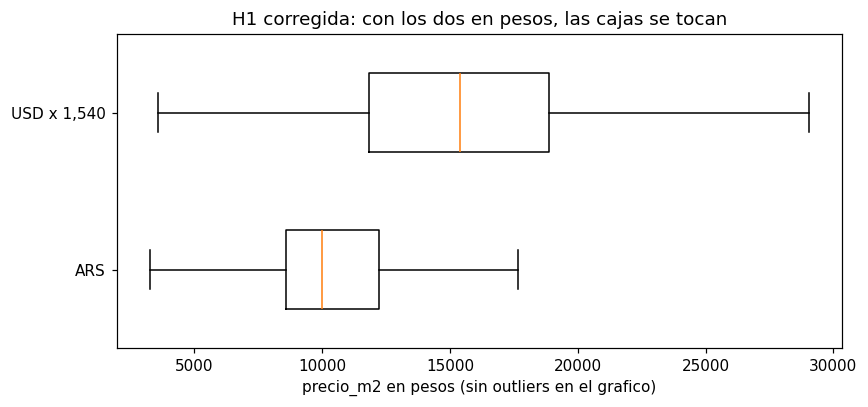

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.boxplot([ars, usd], vert=False, showfliers=False, widths=0.5)
ax.set_yticklabels(["ARS", f"USD x {TC_USD:,.0f}"])
ax.set_xlabel("precio_m2 en pesos (sin outliers en el grafico)")
ax.set_title("H1 corregida: con los dos en pesos, las cajas se tocan")
plt.tight_layout(); plt.show()

**Lectura.** Sin convertir, con este dataset, la separacion da **4,26**
(3,02 en la Entrega 2): una diferencia de escala, sin contenido. Convertidos
cae a **0,84**: sigue en verde, pero al
borde, y **ahora dice algo del mercado**. Los avisos en dolares piden un
**54 % mas por m2** que los publicados en pesos. Son otro segmento: mas
concentrados en Capital y Lujan de Cuyo y mas grandes (85 m2 de mediana
contra 60).

**Campo 6, corregido.** Los avisos en USD **entran al modelo**, convertidos
a pesos (269 filas mas). Como son un segmento mas caro, el modelo recibe la
columna `moneda` como marca de "publicado en dolares": existe en el momento
de predecir (la trae el aviso) y no se calcula con el precio. En la seccion
2.2 se mide cuanto aporta.

## 0.2 Correccion de H3: la distancia al centro, separando por superficie

**Que dijimos en la Entrega 2.** Spearman **-0,087** entre `dist_centro_km` y
`precio_m2`: zona roja, H3 refutada, sin movimiento.

**Lo que nos marcaron.** Que habia que separar los departamentos por
sectores de metros cuadrados y comparar la distancia **dentro de cada
sector**. Es el movimiento de **controlar una tercera variable**: el precio
por m2 depende muchisimo de la superficie (H2), y un monoambiente en el
centro y un departamento de 120 m2 en Chacras no se comparan en la misma
nube.

**Como lo medimos.** Cinco sectores de superficie cubierta (hasta 40 m2, 40
a 55, 55 a 75, 75 a 100 y mas de 100), solo el aglomerado (hasta 30 km), y
en cada sector la correlacion de Spearman con su zona del semaforo. Abajo,
las medianas por anillo de distancia, para ver la forma.

In [4]:
h3 = limpio[limpio["dist_centro_km"].notna() & (limpio["dist_centro_km"] <= 30)].copy()
h3["sector_m2"] = pd.cut(h3["superficie_cubierta_m2"], [0, 40, 55, 75, 100, 1000],
                         labels=["hasta 40", "40-55", "55-75", "75-100", "mas de 100"])
h3["anillo_km"] = pd.cut(h3["dist_centro_km"], [0, 2, 4, 7, 12, 30],
                         labels=["0-2", "2-4", "4-7", "7-12", "12-30"])

def zona(r):
    r = abs(r)
    return "ROJA" if r < 0.2 else ("AMARILLA" if r <= 0.6 else "VERDE")

filas = [{"sector": "TODOS (como en la Entrega 2)", "avisos": len(h3),
          "spearman": h3["dist_centro_km"].corr(h3["precio_m2_ars"], method="spearman")}]
for sector, x in h3.groupby("sector_m2", observed=True):
    filas.append({"sector": sector, "avisos": len(x),
                  "spearman": x["dist_centro_km"].corr(x["precio_m2_ars"], method="spearman")})
tabla_h3 = pd.DataFrame(filas).set_index("sector")
tabla_h3["zona"] = tabla_h3["spearman"].map(zona)
tabla_h3["spearman"] = tabla_h3["spearman"].round(3)
tabla_h3

,avisos,spearman,zona
sector,,,
TODOS (como en la Entrega 2),3134,-0.06,ROJA
hasta 40,459,-0.27,AMARILLA
40-55,787,-0.13,ROJA
55-75,1054,-0.02,ROJA
75-100,606,-0.06,ROJA
mas de 100,228,0.10,ROJA


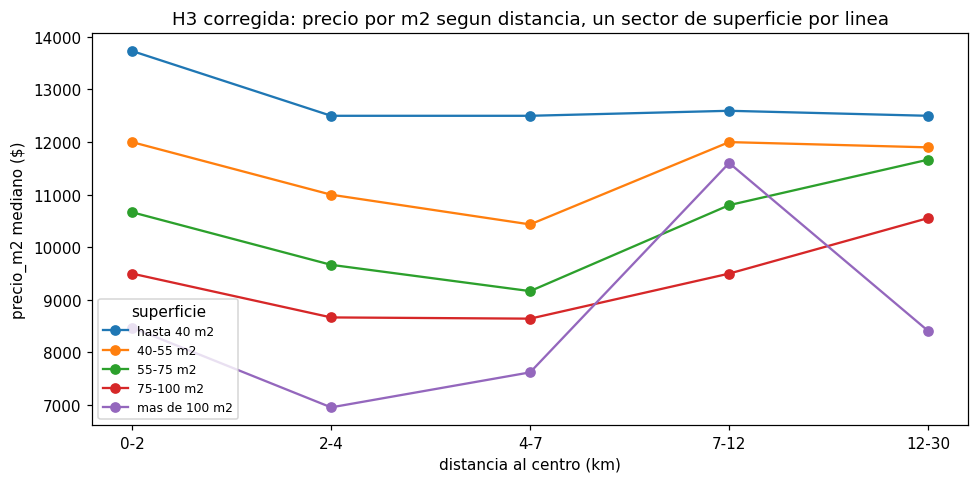

Medianas de precio_m2 por anillo y sector:
sector_m2  hasta 40     40-55     55-75    75-100  mas de 100
anillo_km                                                    
0-2       13,732.00 12,000.00 10,667.00  9,500.00    8,475.00
2-4       12,500.00 11,000.00  9,667.00  8,667.00    6,957.00
4-7       12,500.00 10,435.00  9,167.00  8,643.00    7,622.00
7-12      12,595.00 12,000.00 10,801.00  9,500.00   11,603.00
12-30     12,500.00 11,900.00 11,667.00 10,556.00    8,409.00

Avisos por celda (las de menos de ~20 avisos se leen con cuidado):
sector_m2  hasta 40  40-55  55-75  75-100  mas de 100
anillo_km                                            
0-2             192    251    316     255         125
2-4             133    238    260     161          33
4-7              97    195    263      84          16
7-12             26     63    130      74          38
12-30            11     40     85      32          16


In [5]:
medianas = h3.pivot_table(index="anillo_km", columns="sector_m2", values="precio_m2_ars",
                          aggfunc="median", observed=True)
conteo = h3.pivot_table(index="anillo_km", columns="sector_m2", values="precio_m2_ars",
                        aggfunc="size", observed=True)

fig, ax = plt.subplots(figsize=(9, 4.5))
for sector in medianas.columns:
    ax.plot(medianas.index.astype(str), medianas[sector], marker="o", label=f"{sector} m2")
ax.set_xlabel("distancia al centro (km)")
ax.set_ylabel("precio_m2 mediano ($)")
ax.set_title("H3 corregida: precio por m2 segun distancia, un sector de superficie por linea")
ax.legend(title="superficie", fontsize=8)
plt.tight_layout(); plt.show()

print("Medianas de precio_m2 por anillo y sector:")
print(medianas.round(0).to_string())
print()
print("Avisos por celda (las de menos de ~20 avisos se leen con cuidado):")
print(conteo.to_string())

**Lectura.** Separando por superficie aparece lo que la correlacion global
escondia, y son **dos cosas**:

1. **En los departamentos chicos la distancia si pesa.** Hasta 40 m2 la
   correlacion es **-0,27, zona AMARILLA**: los monoambientes y departamentos
   chicos cerca del centro se alquilan mas caros por m2 (el que alquila uno
   chico paga por estar cerca). En 40-55 m2 el efecto ya es mas debil
   (-0,13, rojo) y de 55 m2 para arriba desaparece.
2. **La relacion no es una recta, es una U.** En casi todos los sectores el
   precio por m2 **baja** del centro hasta los 4-7 km y **vuelve a subir**
   a partir de los 7 km: ahi estan las zonas residenciales caras de Lujan
   de Cuyo y el oeste de Godoy Cruz (Chacras de Coria, Dalvian, Palmares).
   Una correlacion mide si algo sube o baja de forma monotona, y una U
   tiene las dos cosas a la vez: por eso daba casi cero.

**Veredicto, corregido.** H3 como estaba escrita ("a mas distancia, menor
precio por m2") **se confirma solo para los departamentos chicos**; para el
resto no es monotona. **Campo 6, corregido:** en la Entrega 2 decidimos que
`dist_centro_km` no entraba al modelo. **Entra**, porque la relacion existe
aunque no sea una recta, y un modelo de arboles puede usar una U y una
interaccion con la superficie sin que se las especifiquemos. Las secciones
2.2 y 3.3 miden si efectivamente la usa.

## 1. El planteo

### 1.1 Que filas entran

Tres filtros, ninguno estadistico, y una conversion:

- **Con moneda.** 10 avisos no publican precio ni moneda.
- **Todo en pesos.** Los avisos en USD se convierten con `TC_USD`
  (seccion 0.1). Es la definicion del objetivo, no una feature: usa una
  constante, no una estadistica del dataset, asi que no filtra nada del
  test.
- **Sin `motivo_sospecha`.** Son los avisos con superficie imposible
  (menos de 10 m2 o mas de 1000) o con precio de venta cargado como alquiler.
  El pipeline los marca; aca se filtran.
- **Con objetivo.** Sin `precio_m2` no hay nada contra que medir.

In [6]:
paso1 = df[df["moneda"].notna()]
paso2 = paso1[paso1["motivo_sospecha"].isna()]
datos = paso2[paso2["precio_m2"].notna()].copy().reset_index(drop=True)
datos["precio_m2"] = np.where(datos["moneda"] == "USD", datos["precio_m2"] * TC_USD, datos["precio_m2"])

print(f"dataset completo        {len(df):>5}")
print(f"con moneda              {len(paso1):>5}")
print(f"sin motivo_sospecha     {len(paso2):>5}")
print(f"con precio_m2           {len(datos):>5}   <- filas que se modelan")
print("  de las cuales en USD convertidas:", int((datos["moneda"] == "USD").sum()))
print()
print(datos["precio_m2"].describe().round(0))

dataset completo         3539
con moneda               3529
sin motivo_sospecha      3448
con precio_m2            3364   <- filas que se modelan
  de las cuales en USD convertidas: 269

count    3,364.00
mean    11,173.00
std      4,440.00
min        647.00
25%      8,667.00
50%     10,500.00
75%     12,690.00
max     99,000.00
Name: precio_m2, dtype: float64


### 1.2 La metrica, declarada antes de elegir: MAE en pesos por m2

**Que error es mas caro en este problema.** La aplicacion va a marcar avisos
como *sobrevalorados* u *oportunidades* segun cuanto se alejan de lo que
estima el modelo. El error que sale caro es el **sistematico**: estimar mal
el valor de mercado de *muchos* avisos, porque eso los marca mal a todos. Un
aviso aislado con un precio absurdo no deberia arrastrar al modelo.

**Por que MAE y no RMSE.** El RMSE eleva los errores al cuadrado, asi que un
par de avisos con precios mal cargados (el maximo de `precio_m2` es 99.000
contra una mediana de 10.500) dominarian la metrica y el ajuste. El MAE pesa
todos los errores por igual y se lee en las unidades del objetivo:
**"le erramos por X pesos por m2 en promedio"**.

**Por que no R2.** No dice nada en pesos, y no se compara directamente con
el piso.

**Lectura secundaria** (no se usa para elegir): el error relativo mediano,
`|real - predicho| / real`, porque la aplicacion termina razonando en
porcentajes ("este aviso pide un 25 % mas que el mercado").

### 1.3 Como se parten los datos: por firma de inmueble, no al azar

**Las filas no son del todo independientes.** La unidad de analisis es el
aviso, pero el mismo departamento puede estar publicado en los dos portales,
o varias unidades iguales del mismo edificio publicadas por separado. Si una
copia cae en entrenamiento y otra en validacion, el modelo "predice" un
precio que ya vio: la validacion da un numero mas lindo que el real.

**El criterio de agrupamiento** es la misma *firma* que usa el pipeline para
`posible_duplicado_cruzado`: direccion normalizada + localidad + superficie
cubierta. Los avisos sin direccion quedan cada uno en su propio grupo.

**Como se va a usar el modelo:** sobre un aviso que no vio nunca. Por eso
la misma firma **nunca queda de los dos lados**, ni en el corte de test ni en
los folds de validacion cruzada (`GroupShuffleSplit` y `GroupKFold` con
`groups=`).

**Por que no por fecha (`TimeSeriesSplit`).** Se considero. La fecha que
tiene cada aviso es la *ultima vez que se lo vio*, no cuando aparecio, y el
58 % de las filas tiene la misma fecha (13/10, la ultima corrida): no hay un
orden temporal limpio para cortar. Lo que si queda declarado es el supuesto
de la Entrega 2: la ventana es de 5 semanas y no se deflacta por IPC.

In [7]:
direccion_norm = (datos["direccion"].fillna("").str.lower()
                  .str.replace(r"[^a-z0-9]+", "", regex=True))
firma = (direccion_norm + "|" + datos["localidad"].fillna("").str.lower()
         + "|" + datos["superficie_cubierta_m2"].astype(str))
firma = firma.where(direccion_norm != "", datos["clave"])   # sin direccion: grupo propio
grupos = pd.Series(pd.factorize(firma)[0], index=datos.index, name="grupo")

tam = grupos.map(grupos.value_counts())
print("filas:", len(datos), "| grupos distintos:", grupos.nunique())
print("filas que comparten firma con otra:", int((tam > 1).sum()),
      f"({(tam > 1).mean():.1%})")
print("grupo mas grande:", int(tam.max()), "avisos")
print()
print("Ejemplo: el mismo departamento en los dos portales")
ej = datos.loc[tam > 1, ["fuente", "direccion", "localidad", "superficie_cubierta_m2", "precio", "precio_m2"]]
ej = ej.assign(grupo=grupos[tam > 1]).sort_values("grupo")
print(ej[ej.groupby("grupo")["fuente"].transform("nunique") > 1].head(6).to_string())

filas: 3364 | grupos distintos: 2937
filas que comparten firma con otra: 802 (23.8%)
grupo mas grande: 7 avisos

Ejemplo: el mismo departamento en los dos portales
        fuente                direccion   localidad  superficie_cubierta_m2     precio  precio_m2  grupo
22      inmoup         Batalla de Maipú       Maipu                   60.00 420,000.00   7,000.00     22
222  inmoclick         Batalla de MaipÃ       Maipu                   60.00 420,000.00   7,000.00     22
585  inmoclick  Santiago del Estero 420  Godoy Cruz                   45.00 700,000.00  15,555.56     25
25      inmoup  Santiago del Estero 420  Godoy Cruz                   45.00 720,000.00  16,000.00     25
29      inmoup               MITRE 2684     Capital                   47.00 420,000.00   8,936.17     29
267  inmoclick               MITRE 2684     Capital                   47.00 420,000.00   8,936.17     29


**El corte de test.** 20 % de los grupos se separan ahora y no se vuelven a
mirar hasta la seccion 3. Todo lo que se elige (modelo, columnas,
hiperparametros) se elige con validacion cruzada **sobre el 80 % restante**.

In [8]:
# Columnas candidatas: las que la tabla de la Entrega 2 dejo entrar, en crudo.
# Todo lo que se deriva de ellas se hace adentro del pipeline (seccion 1.5).
COLUMNAS = [
    "superficie_cubierta_m2", "superficie_total_m2", "dormitorios", "banos",
    "antiguedad", "cochera", "estado_conservacion", "valor_expensas",
    "tiene_expensas", "acepta_mascotas", "localidad", "zona_geo",
    "dist_centro_km", "densidad_1km", "tipo_anunciante", "fuente",
    "fecha_scraping", "moneda",
]
X = datos[COLUMNAS]
y = datos["precio_m2"]

corte = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEMILLA)
idx_train, idx_test = next(corte.split(X, y, groups=grupos))
X_train, X_test = X.iloc[idx_train], X.iloc[idx_test]
y_train, y_test = y.iloc[idx_train], y.iloc[idx_test]
g_train, g_test = grupos.iloc[idx_train], grupos.iloc[idx_test]

print("train:", len(X_train), "filas |", "test:", len(X_test), "filas")
print("firmas compartidas entre train y test:", len(set(g_train) & set(g_test)))
print(f"mediana precio_m2  train {y_train.median():,.0f}  |  test {y_test.median():,.0f}")

train: 2688 filas | test: 676 filas
firmas compartidas entre train y test: 0
mediana precio_m2  train 10,462  |  test 10,620


### 1.4 El piso: un modelo que no mira ninguna columna

`DummyRegressor(strategy="median")`: predice siempre la mediana del
entrenamiento. Es la mediana y no la media porque, con MAE, la constante que
minimiza el error es la mediana. Se mide **con la misma validacion que todo
lo demas**: 5 folds agrupados, repetidos 3 veces con semillas distintas (15
mediciones), para tener media y desvio.

In [9]:
def cv_agrupada(rep):
    """5 folds por firma; la repeticion cambia como se barajan los grupos."""
    return GroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA + rep)

def medir(modelo, X_, y_, g_, repeticiones=3):
    """MAE de cada fold (5 x repeticiones), con la misma particion para todos los modelos."""
    maes = []
    for rep in range(repeticiones):
        r = cross_validate(modelo, X_, y_, groups=g_, cv=cv_agrupada(rep),
                           scoring="neg_mean_absolute_error")
        maes.extend(-r["test_score"])
    return np.array(maes)

mae_piso = medir(DummyRegressor(strategy="median"), X_train, y_train, g_train)
print(f"PISO (mediana): MAE = {mae_piso.mean():,.0f} +/- {mae_piso.std():,.0f} $/m2")

PISO (mediana): MAE = 2,667 +/- 88 $/m2


### 1.5 Todo adentro de un pipeline

El objeto que se entrena hace, en este orden:

1. **Derivar columnas** (`FunctionTransformer`): normalizar `cochera` (7
   textos distintos -> si/no), unificar `estado_conservacion`, pasar los
   booleanos con muchos nulos a tres estados (si / no / sin dato, decision de
   la Entrega 2), agrupar las localidades del interior (13 filas en 4
   departamentos), convertir `fecha_scraping` en dias desde el inicio de la
   ventana, y `moneda` en una marca 0/1 de "publicado en dolares". Son transformaciones fila por fila, sin estadisticas del dataset,
   pero igual van adentro: el modelo que use la aplicacion tiene que recibir
   el aviso crudo.
2. **Imputar** con la mediana del *fold de entrenamiento*, agregando una
   columna indicadora de "faltaba" (en `antiguedad` falta el 43 %, y que
   falte puede decir algo).
3. **Logaritmo** de superficies y expensas (H2: la relacion con el precio es
   curva; en log-log se endereza).
4. **Escalar** (solo para los modelos lineales; a los arboles no les cambia
   nada).
5. **One-hot** de las categoricas, juntando en "otros" las categorias con
   menos de 10 filas.

In [10]:
LOCALIDADES_GRANDES = ["Capital", "Godoy Cruz", "Guaymallen", "Lujan de Cuyo", "Las Heras", "Maipu"]
INICIO_VENTANA = pd.Timestamp("2026-09-07")

def derivar_columnas(X_):
    # Cada paso se aplica solo si la columna esta: asi el mismo pipeline sirve
    # cuando se prueba el modelo sacando una columna (seccion 2.2).
    X_ = X_.copy()
    if "cochera" in X_:
        cochera = X_["cochera"].astype(object)
        X_["cochera"] = np.where(cochera.isna() | (cochera == "Indistinto"), np.nan,
                                 np.where(cochera == "Sin Cochera", 0.0, 1.0)).astype(float)
    if "estado_conservacion" in X_:
        X_["estado_conservacion"] = (X_["estado_conservacion"]
            .replace({"---": np.nan, "Recicled": "Bueno", "Regular": "Bueno", "Semi new": "Muy Bueno"})
            .fillna("sin_dato"))
    for col in ["tiene_expensas", "acepta_mascotas"]:
        if col in X_:
            X_[col] = X_[col].astype(str).str.lower().map({"true": "si", "false": "no"}).fillna("sin_dato")
    if "localidad" in X_:
        X_["localidad"] = X_["localidad"].where(X_["localidad"].isin(LOCALIDADES_GRANDES), "Interior")
    if "zona_geo" in X_:
        X_["zona_geo"] = X_["zona_geo"].fillna(-2).astype(int).astype(str)   # -2 = sin coordenadas
    if "moneda" in X_:
        X_["moneda"] = (X_["moneda"] == "USD").astype(float)        # 1 = publicado en dolares
    if "fecha_scraping" in X_:
        X_["fecha_scraping"] = (pd.to_datetime(X_["fecha_scraping"]) - INICIO_VENTANA).dt.days
    return X_

LOGARITMICAS = ["superficie_cubierta_m2", "superficie_total_m2", "valor_expensas"]
NUMERICAS = ["dormitorios", "banos", "antiguedad", "cochera", "dist_centro_km",
             "densidad_1km", "fecha_scraping", "moneda"]
CATEGORICAS = ["estado_conservacion", "tiene_expensas", "acepta_mascotas",
               "localidad", "zona_geo", "tipo_anunciante", "fuente"]

def armar_pipeline(estimador, columnas=COLUMNAS, escalar=True):
    """Pipeline completo: derivar -> imputar -> log -> escalar -> one-hot -> modelo."""
    esc = [StandardScaler()] if escalar else []
    log_ = [c for c in LOGARITMICAS if c in columnas]
    num_ = [c for c in NUMERICAS if c in columnas]
    cat_ = [c for c in CATEGORICAS if c in columnas]
    partes = []
    if log_:
        partes.append(("log", make_pipeline(SimpleImputer(strategy="median", add_indicator=True),
                                            FunctionTransformer(np.log1p), *esc), log_))
    if num_:
        partes.append(("num", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), *esc), num_))
    if cat_:
        partes.append(("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10), cat_))
    return Pipeline([
        ("seleccion", FunctionTransformer(lambda X_: X_[columnas])),
        ("derivar", FunctionTransformer(derivar_columnas)),
        ("preparar", ColumnTransformer(partes)),
        ("modelo", estimador),
    ])

# Verificacion: el pipeline corre de punta a punta y no deja nulos
_prep = armar_pipeline(LinearRegression())[:-1].fit(X_train)
_mat = _prep.transform(X_train)
print("matriz que ve el modelo:", _mat.shape, "| nulos:", int(np.isnan(_mat).sum()))

matriz que ve el modelo: (2688, 48) | nulos: 0


### 1.6 Que le pasaria al numero si los pedazos se armaran al azar

La consigna avisa que una validacion al azar sobre filas no independientes
da numeros mas altos que los reales, sin dar ningun aviso. Aca esta medido:
**el mismo modelo**, con `KFold` al azar y con `GroupKFold` por firma.

In [11]:
hgb = armar_pipeline(HistGradientBoostingRegressor(loss="absolute_error", random_state=SEMILLA), escalar=False)

al_azar, agrupada = [], []
for rep in range(3):
    al_azar.extend(-cross_validate(hgb, X_train, y_train, scoring="neg_mean_absolute_error",
                                   cv=KFold(5, shuffle=True, random_state=SEMILLA + rep))["test_score"])
    agrupada.extend(-cross_validate(hgb, X_train, y_train, groups=g_train, scoring="neg_mean_absolute_error",
                                    cv=cv_agrupada(rep))["test_score"])
al_azar, agrupada = np.array(al_azar), np.array(agrupada)
print(f"KFold al azar         MAE = {al_azar.mean():,.0f} +/- {al_azar.std():,.0f}")
print(f"GroupKFold por firma  MAE = {agrupada.mean():,.0f} +/- {agrupada.std():,.0f}")
print(f"diferencia: {agrupada.mean() - al_azar.mean():,.0f} $/m2 de error que el azar escondia")

KFold al azar         MAE = 1,651 +/- 136
GroupKFold por firma  MAE = 1,758 +/- 69
diferencia: 107 $/m2 de error que el azar escondia


**Lectura.** Al azar, el modelo parece errar menos. La diferencia es
exactamente lo que el modelo "acierta" porque vio el mismo departamento (o
su gemelo del mismo edificio) en entrenamiento. Con el corte agrupado ese
atajo no existe, y el numero que queda es el que se puede esperar sobre un
aviso nuevo.

## 2. La comparacion

### 2.1 El modelo simple primero, y dos familias mas

Todos con **las mismas columnas, el mismo pipeline y la misma validacion**
(los mismos 15 folds), con sus valores por defecto razonables. Se ajusta solo
el que se elija.

| Modelo | Familia | Por que esta |
|---|---|---|
| Regresion lineal | lineal | La referencia: si nada le gana, se queda este |
| Regresion lineal sobre log(`precio_m2`) | lineal | El objetivo tiene cola a la derecha; en log los errores relativos pesan parecido |
| Random Forest | arboles (bagging) | Captura no linealidades e interacciones sin suponer forma |
| HistGradientBoosting (perdida absoluta) | boosting | Idem, y optimiza directamente el error absoluto |

In [12]:
MODELOS = {
    "Piso (mediana)": DummyRegressor(strategy="median"),
    "Lineal": armar_pipeline(LinearRegression()),
    "Lineal log(y)": TransformedTargetRegressor(armar_pipeline(LinearRegression()),
                                                func=np.log, inverse_func=np.exp),
    "Random Forest": armar_pipeline(RandomForestRegressor(n_estimators=300, min_samples_leaf=3,
                                                          n_jobs=-1, random_state=SEMILLA), escalar=False),
    "HistGradientBoosting": armar_pipeline(HistGradientBoostingRegressor(loss="absolute_error",
                                                                         random_state=SEMILLA), escalar=False),
}

maes = {n: (mae_piso if n.startswith("Piso") else medir(m, X_train, y_train, g_train))
        for n, m in MODELOS.items()}

tabla = pd.DataFrame({
    "MAE medio": {n: v.mean() for n, v in maes.items()},
    "desvio": {n: v.std() for n, v in maes.items()},
    "mejora vs piso": {n: 1 - v.mean() / mae_piso.mean() for n, v in maes.items()},
})
tabla["mejora vs piso"] = tabla["mejora vs piso"].map("{:.1%}".format)
tabla.round(0)

,MAE medio,desvio,mejora vs piso
Piso (mediana),"2,667.00",88.00,0.0%
Lineal,"1,949.00",94.00,26.9%
Lineal log(y),"1,822.00",75.00,31.7%
Random Forest,"1,820.00",66.00,31.8%
HistGradientBoosting,"1,758.00",69.00,34.1%


**Le gana el complejo al simple por mas que el desvio?** El desvio de cada
modelo mezcla dos cosas: lo dificil que es cada fold (igual para todos) y lo
que cambia el modelo. Como los 15 folds son **los mismos** para todos, la
comparacion justa es fold contra fold: la diferencia de MAE en cada uno, su
media y su desvio.

In [13]:
mejor = "HistGradientBoosting"
filas = []
for otro in ["Lineal", "Lineal log(y)", "Random Forest"]:
    dif = maes[otro] - maes[mejor]
    filas.append({"contra": otro, "le gana por (media)": dif.mean(), "desvio de la diferencia": dif.std(),
                  "folds que gana": f"{(dif > 0).sum()} de {len(dif)}"})
pd.DataFrame(filas).set_index("contra").round(0)

,le gana por (media),desvio de la diferencia,folds que gana
contra,,,
Lineal,192.00,88.00,15 de 15
Lineal log(y),64.00,59.00,14 de 15
Random Forest,62.00,45.00,14 de 15


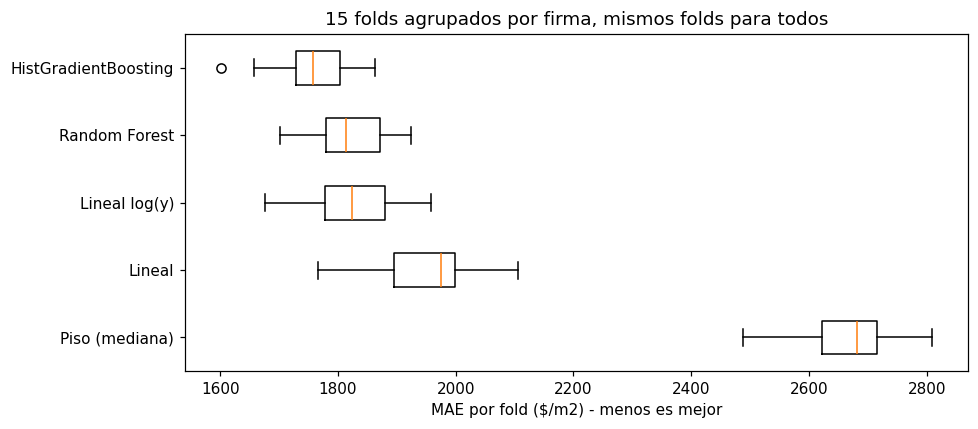

In [14]:
fig, ax = plt.subplots(figsize=(9, 4))
orden = list(maes.keys())
ax.boxplot([maes[n] for n in orden], vert=False)
ax.set_yticklabels(orden)
ax.set_xlabel("MAE por fold ($/m2) - menos es mejor")
ax.set_title("15 folds agrupados por firma, mismos folds para todos")
plt.tight_layout(); plt.show()

**Lectura.** Los cuatro modelos le ganan al piso con holgura: el piso erra
en promedio **2.667 $/m2** y los modelos bajan a **1.750-1.950**. Entre los
modelos, el boosting le gana a la lineal **en los 15 folds**, por 192 $/m2
con un desvio de la diferencia de 88: se justifica el modelo mas complejo.
Contra la lineal en log y contra el bosque la ventaja es mas chica (~63
$/m2, desvio ~50) y gana en 14 de 15; hay que decirlo asi. **Se elige
HistGradientBoosting**, y la lineal en log queda como segunda opcion
defendible (mas facil de explicar, un poco peor).

### 2.2 Las columnas que probamos: cuanto aporta cada una

Para cada columna candidata: se saca, se vuelve a medir el modelo elegido
con los mismos 15 folds, y se compara contra el modelo con todas. Un
**delta positivo** quiere decir que sin esa columna el modelo erra mas (la
columna sirve). Delta cero o negativo: no aporta.

In [15]:
base = maes[mejor]
modelo_hgb = lambda cols: armar_pipeline(HistGradientBoostingRegressor(loss="absolute_error",
                                                                       random_state=SEMILLA),
                                         columnas=cols, escalar=False)
filas = []
for col in COLUMNAS:
    sin = medir(modelo_hgb([c for c in COLUMNAS if c != col]), X_train, y_train, g_train)
    dif = sin - base
    filas.append({"columna": col, "MAE con": base.mean(), "MAE sin": sin.mean(),
                  "delta (sin - con)": dif.mean(), "desvio delta": dif.std(),
                  "folds en que ayuda": (dif > 0).sum()})
ablacion = pd.DataFrame(filas).set_index("columna").sort_values("delta (sin - con)", ascending=False)
ablacion.round(0)

,MAE con,MAE sin,delta (sin - con),desvio delta,folds en que ayuda
columna,,,,,
superficie_cubierta_m2,"1,758.00","1,975.00",217.00,43.00,15
moneda,"1,758.00","1,905.00",147.00,32.00,15
valor_expensas,"1,758.00","1,802.00",44.00,26.00,14
cochera,"1,758.00","1,796.00",38.00,30.00,13
dormitorios,"1,758.00","1,778.00",21.00,30.00,12
estado_conservacion,"1,758.00","1,777.00",19.00,26.00,12
banos,"1,758.00","1,767.00",9.00,22.00,9
dist_centro_km,"1,758.00","1,764.00",6.00,25.00,9
localidad,"1,758.00","1,763.00",5.00,23.00,10


**Regla de decision**, escrita antes de mirar la tabla: una columna **sale**
si sacarla no empeora el MAE en mas de 5 $/m2 de media, o si ayuda en menos
de la mitad de los folds. No se elige por un punto de diferencia: una
columna que no aporta es una columna mas que la aplicacion tiene que pedir y
que puede fallar.

In [16]:
salen = ablacion[(ablacion["delta (sin - con)"] <= 5) | (ablacion["folds en que ayuda"] < 8)].index.tolist()
FINALES = [c for c in COLUMNAS if c not in salen]
print("salen :", salen)
print("quedan:", FINALES)

mae_finales = medir(modelo_hgb(FINALES), X_train, y_train, g_train)
dif = mae_finales - base
print()
print(f"con todas : {base.mean():,.0f} +/- {base.std():,.0f}")
print(f"con las {len(FINALES)} : {mae_finales.mean():,.0f} +/- {mae_finales.std():,.0f}"
      f"   (diferencia {dif.mean():+,.0f}, desvio {dif.std():,.0f})")

salen : ['acepta_mascotas', 'antiguedad', 'tipo_anunciante', 'fuente', 'densidad_1km', 'zona_geo', 'tiene_expensas', 'fecha_scraping', 'superficie_total_m2']
quedan: ['superficie_cubierta_m2', 'dormitorios', 'banos', 'cochera', 'estado_conservacion', 'valor_expensas', 'localidad', 'dist_centro_km', 'moneda']

con todas : 1,758 +/- 69
con las 9 : 1,753 +/- 74   (diferencia -5, desvio 31)


**Lectura.** Salen 9 columnas y el modelo con las 9 restantes erra
**un poco menos** (1.753 contra 1.758): con la mitad de las columnas, el
mismo resultado. Las que conviene tener preparadas:

- **`superficie_cubierta_m2` es la que mas aporta, lejos** (+217 $/m2 si se
  saca, en los 15 folds). Se discute en 3.4 si es una fuga.
- **`moneda` es la segunda** (+147, en los 15 folds). Es la consecuencia de
  la correccion de H1: los avisos en dolares son un segmento 54 % mas caro
  por m2, y sin la marca el modelo los confunde con los de pesos.
- **`valor_expensas` y `cochera` siguen** (+44 y +38): tienen sentido de
  dominio, en Mendoza las expensas y la cochera acompanan a los edificios
  mas nuevos y con mas servicios.
- **`dist_centro_km` queda** (+6, ayuda en 9 de 15), aunque aporta poco:
  es lo que anticipaba la correccion de H3 - la relacion existe pero no es
  una recta.
- **`densidad_1km` y `zona_geo` salen** (-5 y -6): lo que dicen de la
  ubicacion ya lo dicen `dist_centro_km` y `localidad`. `zona_geo` coincide
  con la Entrega 2 (eta cuadrado 0,029, roja).
- **`fecha_scraping` sale** (-12 $/m2): como control de inflacion en una
  ventana de 5 semanas no cambia nada.
- **`superficie_total_m2` sale** (-15): con la cubierta adentro no agrega,
  en casi todos los departamentos son el mismo numero.
- **`antiguedad`, `fuente`, `tipo_anunciante`, `tiene_expensas` y
  `acepta_mascotas` salen**: sacarlas no empeora el error.

### 2.3 El ajuste de hiperparametros del elegido

Grilla sobre los parametros que mas mueven a un boosting: tasa de
aprendizaje, cantidad de arboles, tamano de cada arbol, minimo de filas por
hoja, y la perdida (absoluta, que es nuestra metrica, contra cuadratica).
Validacion: los mismos 5 folds agrupados. **Se muestra la tabla completa**,
no solo el ganador.

In [17]:
grilla = GridSearchCV(
    modelo_hgb(FINALES),
    param_grid={
        "modelo__loss": ["absolute_error", "squared_error"],
        "modelo__learning_rate": [0.03, 0.1],
        "modelo__max_iter": [200, 500],
        "modelo__max_leaf_nodes": [15, 31],
        "modelo__min_samples_leaf": [10, 30],
    },
    scoring="neg_mean_absolute_error",
    cv=cv_agrupada(0),
    n_jobs=-1,
)
grilla.fit(X_train, y_train, groups=g_train)

res = pd.DataFrame(grilla.cv_results_)
cols_param = [c for c in res.columns if c.startswith("param_")]
tabla_grilla = (res[cols_param + ["mean_test_score", "std_test_score", "rank_test_score"]]
                .assign(MAE=lambda d: -d["mean_test_score"], desvio=lambda d: d["std_test_score"])
                .drop(columns=["mean_test_score", "std_test_score"])
                .rename(columns=lambda c: c.replace("param_modelo__", ""))
                .sort_values("rank_test_score"))
tabla_grilla[["MAE", "desvio"]] = tabla_grilla[["MAE", "desvio"]].round(0)
print("mejor combinacion:", {k.replace('modelo__', ''): v for k, v in grilla.best_params_.items()})
tabla_grilla

mejor combinacion: {'learning_rate': 0.03, 'loss': 'absolute_error', 'max_iter': 500, 'max_leaf_nodes': 31, 'min_samples_leaf': 10}


,learning_rate,loss,max_iter,max_leaf_nodes,min_samples_leaf,rank_test_score,MAE,desvio
6,0.03,absolute_error,500,31,10,1,"1,746.00",75.00
22,0.10,absolute_error,500,31,10,2,"1,746.00",80.00
18,0.10,absolute_error,200,31,10,3,"1,748.00",81.00
7,0.03,absolute_error,500,31,30,4,"1,752.00",91.00
20,0.10,absolute_error,500,15,10,5,"1,754.00",92.00
23,0.10,absolute_error,500,31,30,6,"1,754.00",84.00
4,0.03,absolute_error,500,15,10,7,"1,755.00",86.00
21,0.10,absolute_error,500,15,30,8,"1,757.00",90.00
19,0.10,absolute_error,200,31,30,9,"1,758.00",89.00
5,0.03,absolute_error,500,15,30,10,"1,758.00",101.00


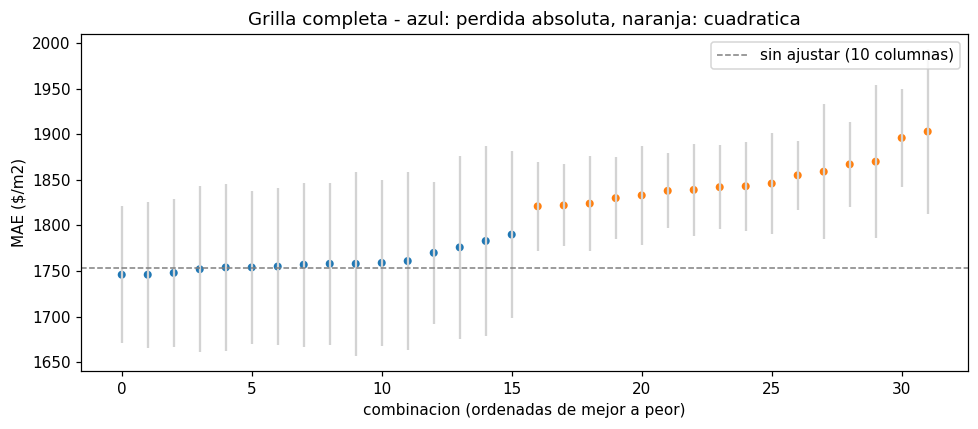

In [18]:
fig, ax = plt.subplots(figsize=(9, 4))
t = tabla_grilla.reset_index(drop=True)
colores = np.where(t["loss"] == "absolute_error", "tab:blue", "tab:orange")
ax.errorbar(t.index, t["MAE"], yerr=t["desvio"], fmt="none", ecolor="lightgray")
ax.scatter(t.index, t["MAE"], c=colores, s=18)
ax.axhline(mae_finales.mean(), ls="--", c="gray", lw=1, label="sin ajustar (10 columnas)")
ax.set_xlabel("combinacion (ordenadas de mejor a peor)")
ax.set_ylabel("MAE ($/m2)")
ax.set_title("Grilla completa - azul: perdida absoluta, naranja: cuadratica")
ax.legend(); plt.tight_layout(); plt.show()

**Lectura.** Las **16 mejores combinaciones usan perdida absoluta**: la
cuadratica recien aparece en el puesto 17. Es lo que se anticipo al elegir
la metrica: optimizar errores al cuadrado persigue a los avisos extremos, y
eso se paga en el error tipico. La mejor combinacion (tasa 0,03, 500
arboles, hojas de 31 nodos y minimo 10 filas) da **1.746 $/m2** contra
**1.753** sin ajustar: mejora 7 $/m2, muchisimo menos que el desvio entre
folds (~75), y la segunda combinacion (tasa 0,1) empata. Hay que decirlo
asi: el ajuste practicamente no mueve el error, los valores por defecto ya
estaban bien, y lo que movio el error fue elegir familia y columnas.

## 3. El modelo final, leido

### 3.1 Medido una vez sobre el test

El modelo con las columnas y los hiperparametros elegidos se entrena con
**todo** el entrenamiento y se mide **una sola vez** sobre el 20 % que se
separo en la seccion 1.3. Despues de esta celda no se cambia nada.

In [19]:
final = grilla.best_estimator_
final.fit(X_train, y_train)

piso_final = DummyRegressor(strategy="median").fit(X_train, y_train)
pred_test = final.predict(X_test)
pred_piso = piso_final.predict(X_test)

mae_test = mean_absolute_error(y_test, pred_test)
mae_piso_test = mean_absolute_error(y_test, pred_piso)
err_rel = (np.abs(y_test - pred_test) / y_test).median()
err_rel_piso = (np.abs(y_test - pred_piso) / y_test).median()

print(f"TEST  modelo  MAE = {mae_test:,.0f} $/m2   error relativo mediano = {err_rel:.1%}")
print(f"TEST  piso    MAE = {mae_piso_test:,.0f} $/m2   error relativo mediano = {err_rel_piso:.1%}")
print(f"mejora sobre el piso: {1 - mae_test / mae_piso_test:.1%}")
print()
print(f"(en validacion cruzada el elegido daba {-grilla.best_score_:,.0f}: "
      "si el test se parece, la validacion estaba bien armada)")

TEST  modelo  MAE = 1,763 $/m2   error relativo mediano = 12.0%
TEST  piso    MAE = 2,778 $/m2   error relativo mediano = 19.1%
mejora sobre el piso: 36.5%

(en validacion cruzada el elegido daba 1,746: si el test se parece, la validacion estaba bien armada)


**Lectura.** En test el modelo erra **1.763 $/m2** contra **2.778** del
piso: **37 % menos error**, y el error relativo mediano baja de 19,1 % a
12,0 %. El MAE de test queda muy cerca del de validacion cruzada (1.746):
la validacion agrupada no estaba inflando el resultado.

**Es mucho o poco para lo que queremos hacer?** En un departamento de 50 m2
con una mediana de ~10.500 $/m2, el alquiler es de unos $525.000 y el error
tipico del modelo es de unos $88.000 por mes. Para la aplicacion de la
Entrega 4 eso quiere decir que **no puede marcar como sobrevalorado un aviso
que pide un 5 % mas que la estimacion**: esa diferencia esta dentro del
error del modelo. Solo tiene sentido marcar los que se alejan bastante mas
que el error tipico (del orden de 20 % o mas).

### 3.2 Donde se equivoca

Real contra predicho, y el error por tramo del objetivo (quintiles del
`precio_m2` real).

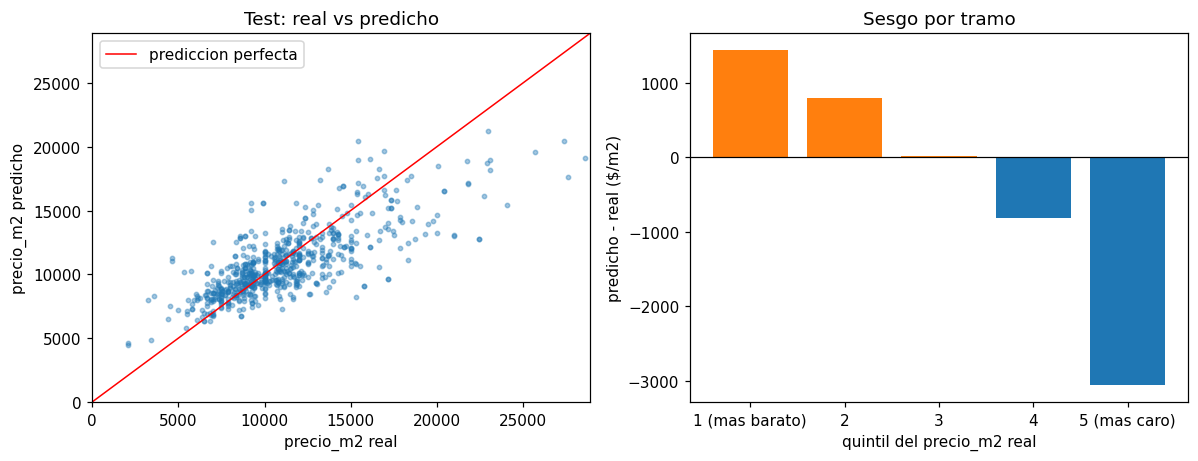

,filas,real_mediano,MAE,sesgo_medio
tramo,,,,
1 (mas barato),139,"7,273.00","1,493.00","1,442.00"
2,133,"9,091.00","1,207.00",800.00
3,140,"10,690.00",987.00,19.00
4,129,"12,019.00","1,613.00",-814.00
5 (mas caro),135,"15,833.00","3,536.00","-3,063.00"


In [20]:
resultado = pd.DataFrame({"real": y_test.values, "predicho": pred_test},
                         index=X_test.index)
resultado["error"] = resultado["predicho"] - resultado["real"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
ax = axes[0]
ax.scatter(resultado["real"], resultado["predicho"], s=8, alpha=0.4)
lim = [0, resultado["real"].quantile(0.995) * 1.05]
ax.plot(lim, lim, c="red", lw=1, label="prediccion perfecta")
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("precio_m2 real"); ax.set_ylabel("precio_m2 predicho")
ax.set_title("Test: real vs predicho"); ax.legend()

resultado["tramo"] = pd.qcut(resultado["real"], 5,
                             labels=["1 (mas barato)", "2", "3", "4", "5 (mas caro)"])
por_tramo = resultado.groupby("tramo", observed=True).agg(
    filas=("real", "size"),
    real_mediano=("real", "median"),
    MAE=("error", lambda e: e.abs().mean()),
    sesgo_medio=("error", "mean"),
)
ax = axes[1]
ax.bar(por_tramo.index.astype(str), por_tramo["sesgo_medio"],
       color=np.where(por_tramo["sesgo_medio"] > 0, "tab:orange", "tab:blue"))
ax.axhline(0, c="black", lw=0.8)
ax.set_xlabel("quintil del precio_m2 real"); ax.set_ylabel("predicho - real ($/m2)")
ax.set_title("Sesgo por tramo")
plt.tight_layout(); plt.show()
por_tramo.round(0)

**Lectura.** El modelo **sobreestima los avisos baratos y subestima los
caros**: en el quintil mas barato predice en promedio 1.442 $/m2 de mas, y
en el mas caro 3.063 de menos, donde ademas el MAE se dispara a 3.536 (el
doble del general). En el medio (quintiles 2 a 4) erra entre 1.000 y 1.600.
Es la regresion hacia la media de cualquier modelo que no tiene la
informacion que explica por que un aviso es caro o barato.

**Desde el dominio:** lo que hace caro un departamento en Mendoza y no esta
en las columnas es el edificio (amenities, seguridad, vista), la calidad de
terminaciones, si esta amoblado (54 % de nulos, salio en la Entrega 2) y la
cuadra exacta - todo eso vive en la `descripcion` y en las fotos, que no
entran al modelo. Para la aplicacion esto importa: **un aviso del tramo caro
tiene mas chance de salir marcado como "sobrevalorado" sin serlo**, porque
el modelo no ve lo que lo justifica.

In [21]:
por_localidad = (resultado.join(X_test["localidad"])
                 .assign(localidad=lambda d: d["localidad"].where(d["localidad"].isin(LOCALIDADES_GRANDES), "Interior"))
                 .groupby("localidad")
                 .agg(filas=("real", "size"), MAE=("error", lambda e: e.abs().mean()),
                      sesgo_medio=("error", "mean"))
                 .sort_values("MAE", ascending=False))
por_localidad.round(0)

,filas,MAE,sesgo_medio
localidad,,,
Interior,2,"2,907.00","-2,465.00"
Maipu,34,"2,284.00",-743.00
Lujan de Cuyo,53,"2,064.00",-910.00
Capital,265,"1,938.00",-401.00
Godoy Cruz,133,"1,874.00",-464.00
Las Heras,54,"1,642.00",301.00
Guaymallen,135,"1,092.00",157.00


In [22]:
# El error por moneda de publicacion: los avisos en USD entraron convertidos (seccion 0.1)
por_moneda = (resultado.join(X_test["moneda"]).groupby("moneda")
              .agg(filas=("real", "size"), real_mediano=("real", "median"),
                   MAE=("error", lambda e: e.abs().mean()), sesgo_medio=("error", "mean")))
por_moneda.round(0)

,filas,real_mediano,MAE,sesgo_medio
moneda,,,,
ARS,620,"10,211.00","1,608.00",-388.00
USD,56,"15,400.00","3,480.00",562.00


**Lectura por localidad y por moneda.** Donde mas erra es en **Maipu**
(MAE ~2.280, solo 34 avisos de test), **Lujan de Cuyo** (~2.060) y
**Capital** (~1.940), y en las tres subestima. Guaymallen es donde mejor
anda (~1.090). Lujan y Capital son donde estan las zonas caras (Chacras, la
Quinta y la Sexta Seccion) mezcladas con departamentos comunes bajo la
misma etiqueta.

Los **avisos en dolares** (56 en test) tienen un error de **3.480 $/m2**,
mas del doble que los de pesos (1.608). Es el costo de haberlos sumado: son
pocos, mas caros y mas dispersos, y el modelo tiene menos de donde
aprender. Pero el error en los avisos en pesos queda **casi igual** que
antes de la correccion (~1.550 a ~1.600), asi que el modelo gana 269
avisos que antes no podia evaluar sin perder casi nada en el resto.

### 3.3 En que se apoya: importancia por permutacion

Sobre el test: se desordena una columna por vez (10 veces) y se mide cuanto
empeora el MAE. Se hace sobre las **columnas crudas** que recibe el
pipeline, asi la importancia se lee en terminos del aviso y no del one-hot.

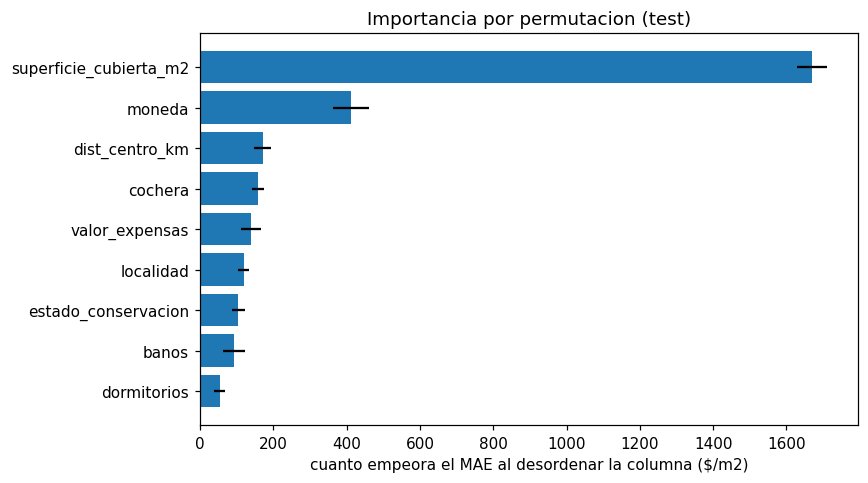

,aumento del MAE,desvio
superficie_cubierta_m2,"1,669.00",41.00
moneda,412.00,49.00
dist_centro_km,171.00,22.00
cochera,159.00,16.00
valor_expensas,139.00,27.00
localidad,120.00,15.00
estado_conservacion,104.00,18.00
banos,94.00,30.00
dormitorios,54.00,14.00


In [23]:
imp = permutation_importance(final, X_test, y_test, scoring="neg_mean_absolute_error",
                             n_repeats=10, random_state=SEMILLA, n_jobs=-1)
importancia = (pd.DataFrame({"aumento del MAE": imp.importances_mean, "desvio": imp.importances_std},
                            index=X_test.columns)
               .loc[FINALES].sort_values("aumento del MAE"))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(importancia.index, importancia["aumento del MAE"], xerr=importancia["desvio"], color="tab:blue")
ax.set_xlabel("cuanto empeora el MAE al desordenar la columna ($/m2)")
ax.set_title("Importancia por permutacion (test)")
plt.tight_layout(); plt.show()
importancia.sort_values("aumento del MAE", ascending=False).round(0)

**Lectura.** `superficie_cubierta_m2` domina: desordenarla sube el error en
~1.670 $/m2, mas que todas las demas juntas. La segunda es **`moneda`**
(~410): la marca de "publicado en dolares" que agrego la correccion de H1.
Despues vienen `dist_centro_km`, `cochera` y `valor_expensas`.

**Por que `dist_centro_km` pesa aca (~170) y en 2.2 aportaba poco (+6)?** Las
dos medidas preguntan cosas distintas. Sacar la columna y reentrenar (2.2)
mide si la informacion **esta en otro lado**: la ubicacion tambien la
cuenta `localidad`, asi que el modelo se arregla sin ella. Desordenarla con
el modelo ya entrenado (aca) mide **cuanto la usa este modelo**: la usa, y
romperla le duele. Las dos lecturas juntas dicen que la ubicacion importa,
pero ninguna de sus columnas es imprescindible por separado.

### 3.4 La columna que mas pesa: es una fuga?

La columna que mas pesa es `superficie_cubierta_m2`, y hay que mirarla con
sospecha porque **esta en la definicion del objetivo**: `precio_m2 = precio
/ superficie_cubierta_m2`.

Tres chequeos para descartar que sea una fuga:

1. **Existe al predecir?** Si: la publica el aviso, igual que los
   dormitorios. No se calcula con el precio ni con nada posterior.
2. **Contiene la respuesta?** No. Contiene la respuesta *solo* si el precio
   fuera constante: ahi `precio_m2` seria `constante / superficie` y la
   superficie la reconstruiria. Lo que si hay es un efecto real del mercado,
   medido en H2: el alquiler crece **menos que proporcional** a la superficie
   (en log-log, pendiente menor que 1), asi que el m2 de un departamento
   grande es mas barato. Eso es justamente lo que tiene que aprender el
   modelo.
3. **Sin ella, el modelo sigue diciendo algo?** Se mide abajo. Si sin la
   superficie el modelo todavia le gana al piso, no depende de un atajo.

Y la otra fuga del proyecto ya esta fuera desde la Entrega 2: `precio` (que
con la superficie despeja el objetivo exacto), y `dias_publicado` /
`veces_visto` (censuradas por la ventana, y valen 0 y 1 para un aviso nuevo).

In [24]:
# Pendiente de log(precio) contra log(superficie) en el entrenamiento: si es < 1,
# el precio crece menos que proporcional y el precio_m2 baja con la superficie.
ok = X_train["superficie_cubierta_m2"].notna()
precio_train = y_train[ok] * X_train.loc[ok, "superficie_cubierta_m2"]
pendiente = np.polyfit(np.log(X_train.loc[ok, "superficie_cubierta_m2"]), np.log(precio_train), 1)[0]
print(f"pendiente log(precio) ~ log(superficie): {pendiente:.2f}  (1 = el precio crece proporcional)")

sin_sup = [c for c in FINALES if c not in ("superficie_cubierta_m2", "superficie_total_m2")]
mae_sin_sup = medir(modelo_hgb(sin_sup), X_train, y_train, g_train)
print(f"MAE CV sin ninguna superficie: {mae_sin_sup.mean():,.0f} +/- {mae_sin_sup.std():,.0f}")
print(f"MAE CV piso                  : {mae_piso.mean():,.0f} +/- {mae_piso.std():,.0f}")
print(f"MAE CV modelo final (CV)     : {-grilla.best_score_:,.0f}")

pendiente log(precio) ~ log(superficie): 0.71  (1 = el precio crece proporcional)
MAE CV sin ninguna superficie: 2,186 +/- 108
MAE CV piso                  : 2,667 +/- 88
MAE CV modelo final (CV)     : 1,746


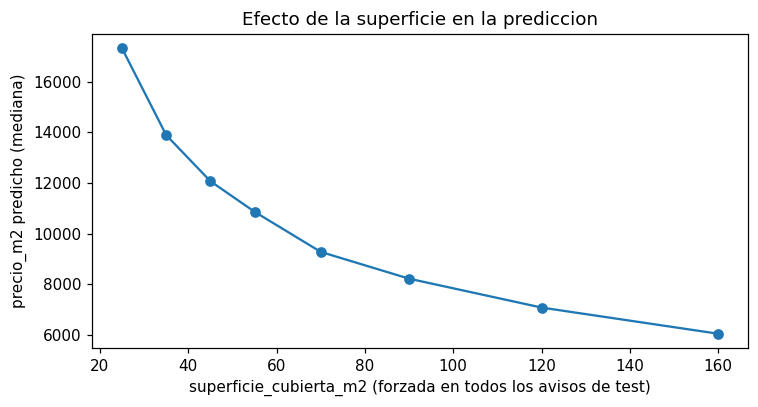

In [25]:
# Como se mueve la prediccion con la superficie, dejando todo lo demas como esta
grid_sup = np.array([25, 35, 45, 55, 70, 90, 120, 160])
curva = []
for s in grid_sup:
    Xs = X_test.copy(); Xs["superficie_cubierta_m2"] = s
    curva.append(np.median(final.predict(Xs)))
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(grid_sup, curva, marker="o")
ax.set_xlabel("superficie_cubierta_m2 (forzada en todos los avisos de test)")
ax.set_ylabel("precio_m2 predicho (mediana)")
ax.set_title("Efecto de la superficie en la prediccion")
plt.tight_layout(); plt.show()

**Lectura.** La pendiente es **0,71**: si la superficie se duplica, el
alquiler sube ~64 % y no 100 %, asi que el m2 de un departamento grande es
mas barato. La curva baja de forma suave (no hay un salto que delate que el
modelo "despeja"), y **sin ninguna superficie** el modelo erra 2.186 $/m2:
peor que con ella (1.746), pero todavia bastante mejor que el piso (2.667).
La superficie pesa porque es la variable que mas explica el precio por m2,
no porque contenga la respuesta.

## 4. Lo que probamos y no anduvo

- **Validacion al azar.** Daba un MAE mas bajo; la diferencia era fuga por
  avisos repetidos (seccion 1.6).
- **Columnas que no aportaron** (seccion 2.2, cada una con su MAE con y
  sin): `antiguedad`, `fuente`, `tipo_anunciante`, `tiene_expensas`,
  `acepta_mascotas`, `densidad_1km`, `zona_geo`, `fecha_scraping` y
  `superficie_total_m2`. En particular `fecha_scraping` como control de la
  inflacion no cambia el error en una ventana de 5 semanas, y `zona_geo` -
  la feature que se construyo con KMeans en la Entrega 2 - no agrega nada.
- **Perdida cuadratica** en el boosting: la primera combinacion con ella
  queda en el puesto 17 de la grilla (seccion 2.3).
- **La grilla de hiperparametros** mejoro solo 7 $/m2, mucho menos que el
  desvio.
- **La lineal sobre el objetivo en log** mejoro a la lineal comun, pero no
  alcanzo al boosting.
- **Lo que queda afuera y explicaria los errores grandes:** el texto de la
  `descripcion` y si el departamento esta amoblado. Material para mas
  adelante.